# Exploratory Data Analysis — Palmer Penguins Dataset

**Goal:** Explore physical measurements of 344 penguins from three species living on three islands in Antarctica, clean the data, and find which features best separate the species.

**Dataset:** Palmer Penguins (Dr. Kristen Gorman, Palmer Station LTER) — 344 rows, 7 columns.

**Steps:** Load → Inspect → Clean → Univariate analysis → Bivariate analysis → Correlation → Outliers → Conclusions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (8, 5)

## 1. Load the data

In [2]:
df = pd.read_csv("penguins.csv")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,gender
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## 2. Inspect structure

In [3]:
print("Shape:", df.shape)
df.info()

Shape: (344, 7)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   gender             333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [4]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [5]:
df.describe(exclude='number')

,species,island,gender
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,Male
freq,152,168,168


## 3. Data cleaning
### 3.1 Missing values

In [6]:
missing = df.isnull().sum()
pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(2)})

,missing,percent
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
gender,11,3.20


In [7]:
# Rows where every measurement is missing carry no information
df[df[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]].isnull().all(axis=1)]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,gender
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


Two rows have no measurements at all → drop them.
`gender` has a few more gaps → fill with the most common gender **within the same species** (mode), so we keep the rest of the row.

In [8]:
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
df = df.dropna(subset=num_cols, how="all")
df["gender"] = df.groupby("species")["gender"].transform(lambda s: s.fillna(s.mode()[0]))
print("Missing after cleaning:\n", df.isnull().sum())
print("Shape:", df.shape)

Missing after cleaning:
 species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
gender               0
dtype: int64
Shape: (342, 7)


### 3.2 Duplicates & data types

In [9]:
print("Duplicate rows:", df.duplicated().sum())
for c in ["species", "island", "gender"]:
    df[c] = df[c].astype("category")
df.dtypes

Duplicate rows: 0


species              category
island               category
bill_length_mm        float64
bill_depth_mm         float64
flipper_length_mm     float64
body_mass_g           float64
gender               category
dtype: object

## 4. Univariate analysis
### 4.1 Categorical columns

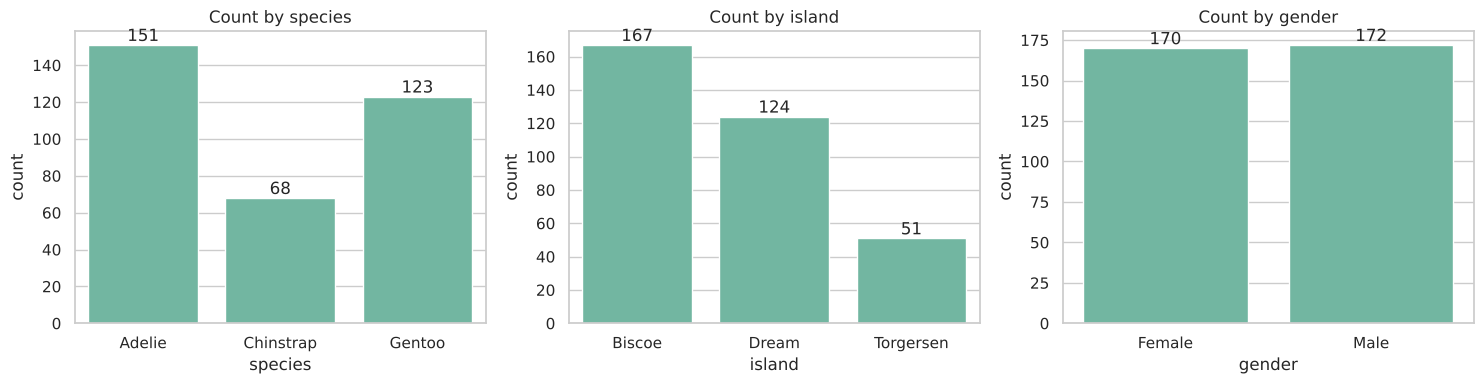

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["species", "island", "gender"]):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Count by {col}")
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom")
plt.tight_layout(); plt.show()

**Observation:** Adelie is the largest group (~44%), Chinstrap the smallest. Biscoe is the biggest island sample. Gender is almost perfectly balanced.

### 4.2 Numerical columns

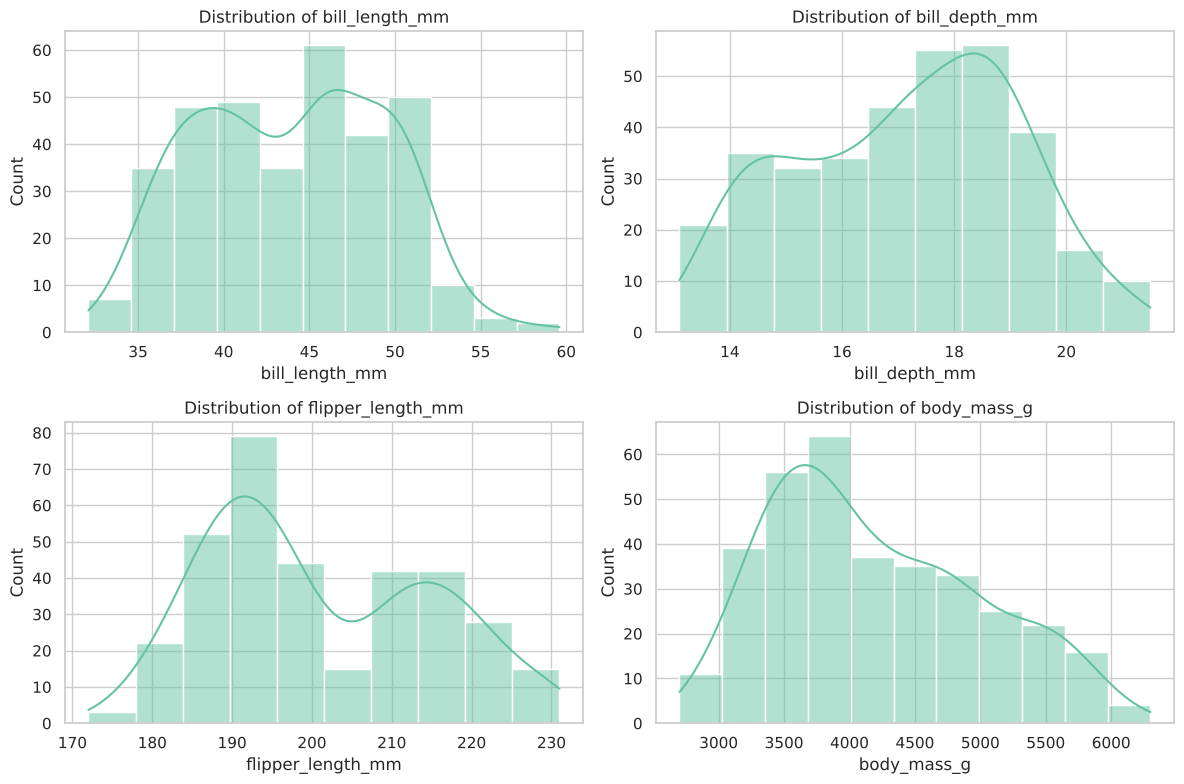

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout(); plt.show()

In [12]:
df[num_cols].skew().round(3).to_frame("skewness")

,skewness
bill_length_mm,0.053
bill_depth_mm,-0.143
flipper_length_mm,0.346
body_mass_g,0.470


**Observation:** Flipper length and bill length look bimodal — a hint that the data mixes groups (species) with different sizes. Body mass is slightly right-skewed. All skew values are small, so no transformation is needed.

## 5. Bivariate analysis
### 5.1 Measurements by species

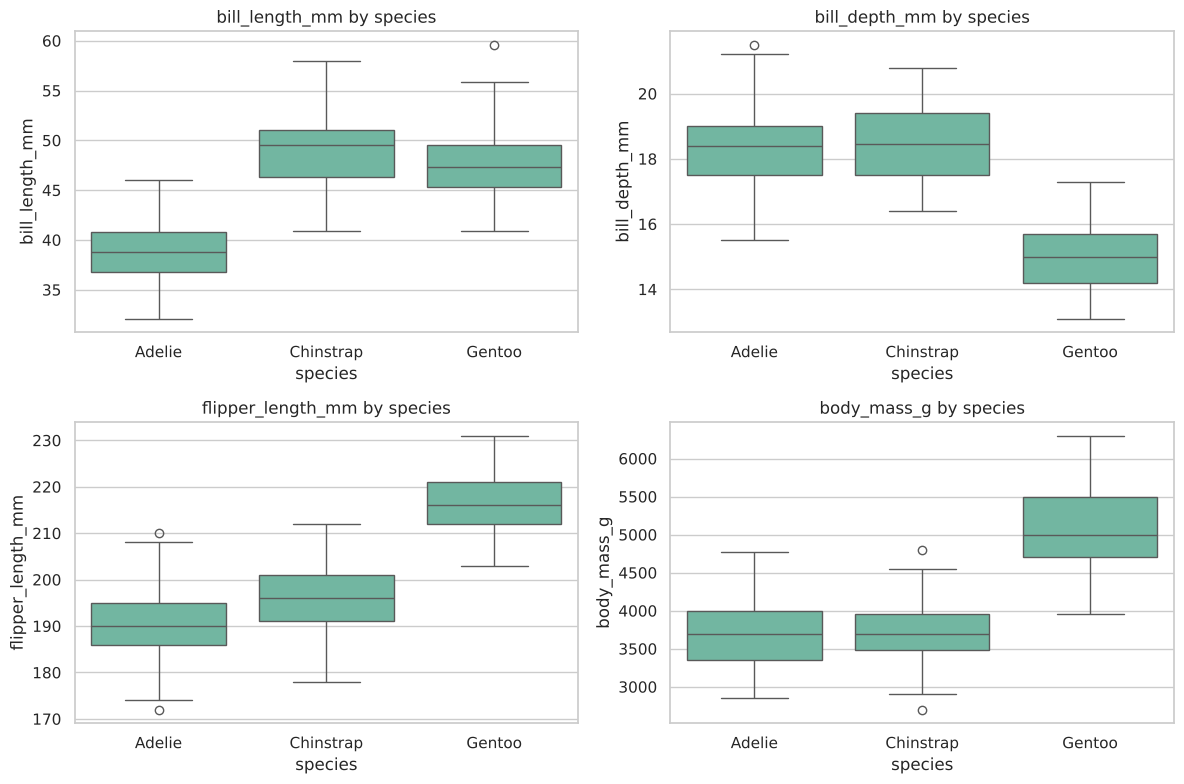

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x="species", y=col, ax=ax)
    ax.set_title(f"{col} by species")
plt.tight_layout(); plt.show()

In [14]:
df.groupby("species", observed=True)[num_cols].mean().round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.8,18.3,190.0,3700.7
Chinstrap,48.8,18.4,195.8,3733.1
Gentoo,47.5,15.0,217.2,5076.0


**Observation:**
- **Gentoo** are the heaviest (~5 kg) with the longest flippers, but have the *shallowest* bills.
- **Adelie** have short bills.
- **Chinstrap** have long bills like Gentoo but deep bills like Adelie.

### 5.2 Species vs island

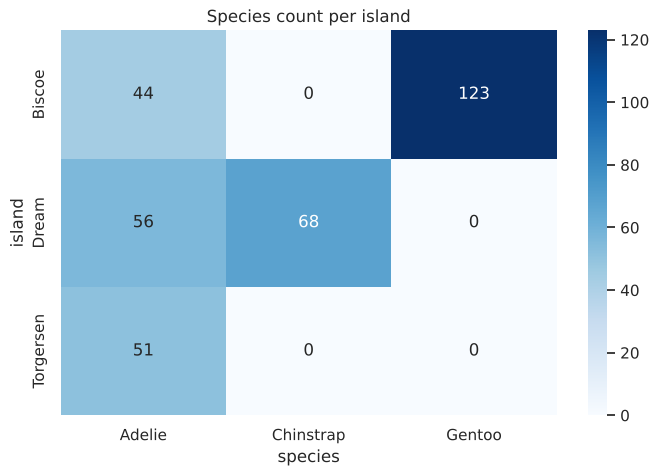

In [15]:
ct = pd.crosstab(df["island"], df["species"])
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Species count per island"); plt.show()

**Observation:** Gentoo live only on Biscoe, Chinstrap only on Dream. Adelie are found on all three islands — island alone is a strong clue to species.

### 5.3 Gender differences

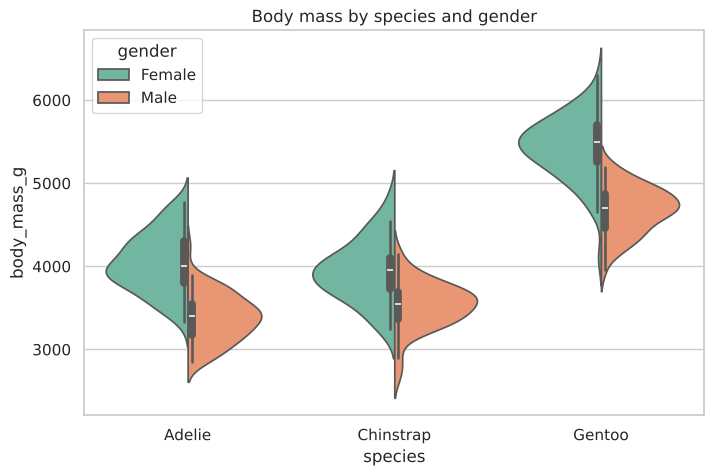

In [16]:
sns.violinplot(data=df, x="species", y="body_mass_g", hue="gender", split=True)
plt.title("Body mass by species and gender"); plt.show()

In [17]:
df.groupby(["species", "gender"], observed=True)["body_mass_g"].mean().unstack().round(0)

gender,Female,Male
species,,
Adelie,3380.0,4043.0
Chinstrap,3527.0,3939.0
Gentoo,4680.0,5430.0


**Observation:** Males are heavier than females in every species; the gap is largest in Gentoo (~800 g).

### 5.4 Bill length vs bill depth

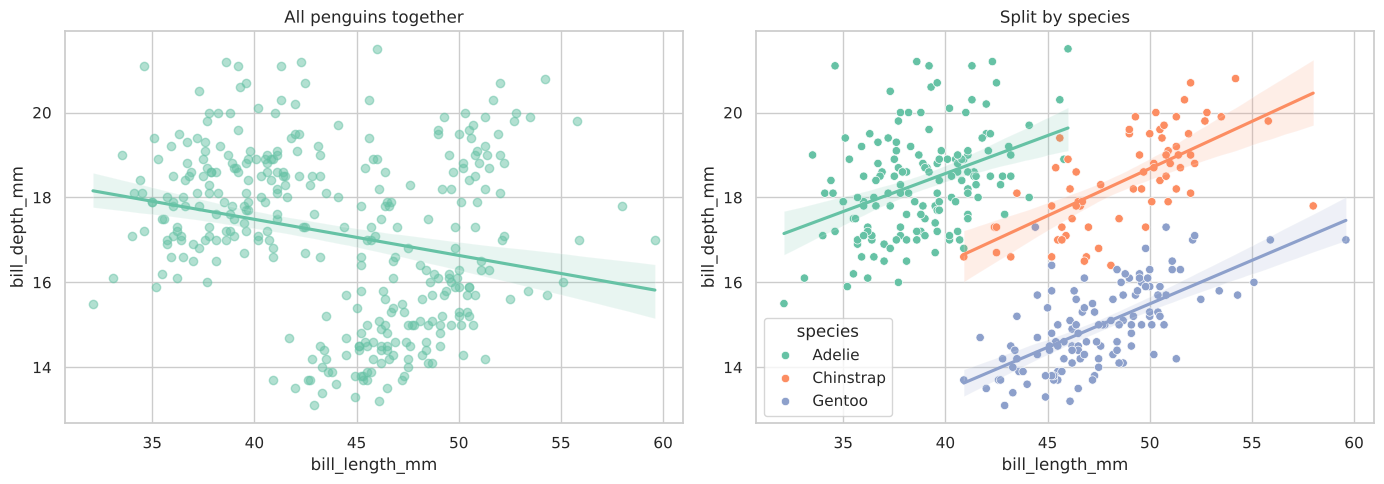

Overall correlation: -0.235
species                  
Adelie     bill_length_mm    0.391
Chinstrap  bill_length_mm    0.654
Gentoo     bill_length_mm    0.643
Name: bill_depth_mm, dtype: float64


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=df, x="bill_length_mm", y="bill_depth_mm", ax=axes[0], scatter_kws={"alpha":0.5})
axes[0].set_title("All penguins together")
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", ax=axes[1])
for sp in df["species"].cat.categories:
    sub = df[df["species"] == sp]
    sns.regplot(data=sub, x="bill_length_mm", y="bill_depth_mm", scatter=False, ax=axes[1])
axes[1].set_title("Split by species")
plt.tight_layout(); plt.show()
print("Overall correlation:", round(df["bill_length_mm"].corr(df["bill_depth_mm"]), 3))
print(df.groupby("species", observed=True)[["bill_length_mm","bill_depth_mm"]].corr().iloc[0::2, 1].round(3))

**Key insight — Simpson's Paradox:** Across all penguins, longer bills seem to go with *shallower* bills (negative correlation). But **inside each species the relationship is positive.** The overall trend is misleading because it mixes three groups. This is why EDA should always check results by group.

## 6. Correlation analysis

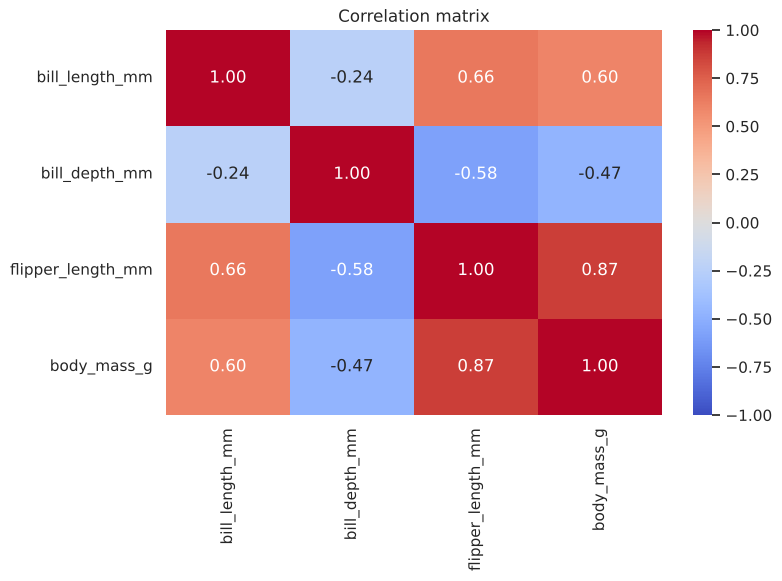

In [19]:
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation matrix"); plt.show()

**Observation:** Flipper length and body mass are strongly correlated (≈0.87) — bigger penguins have longer flippers.

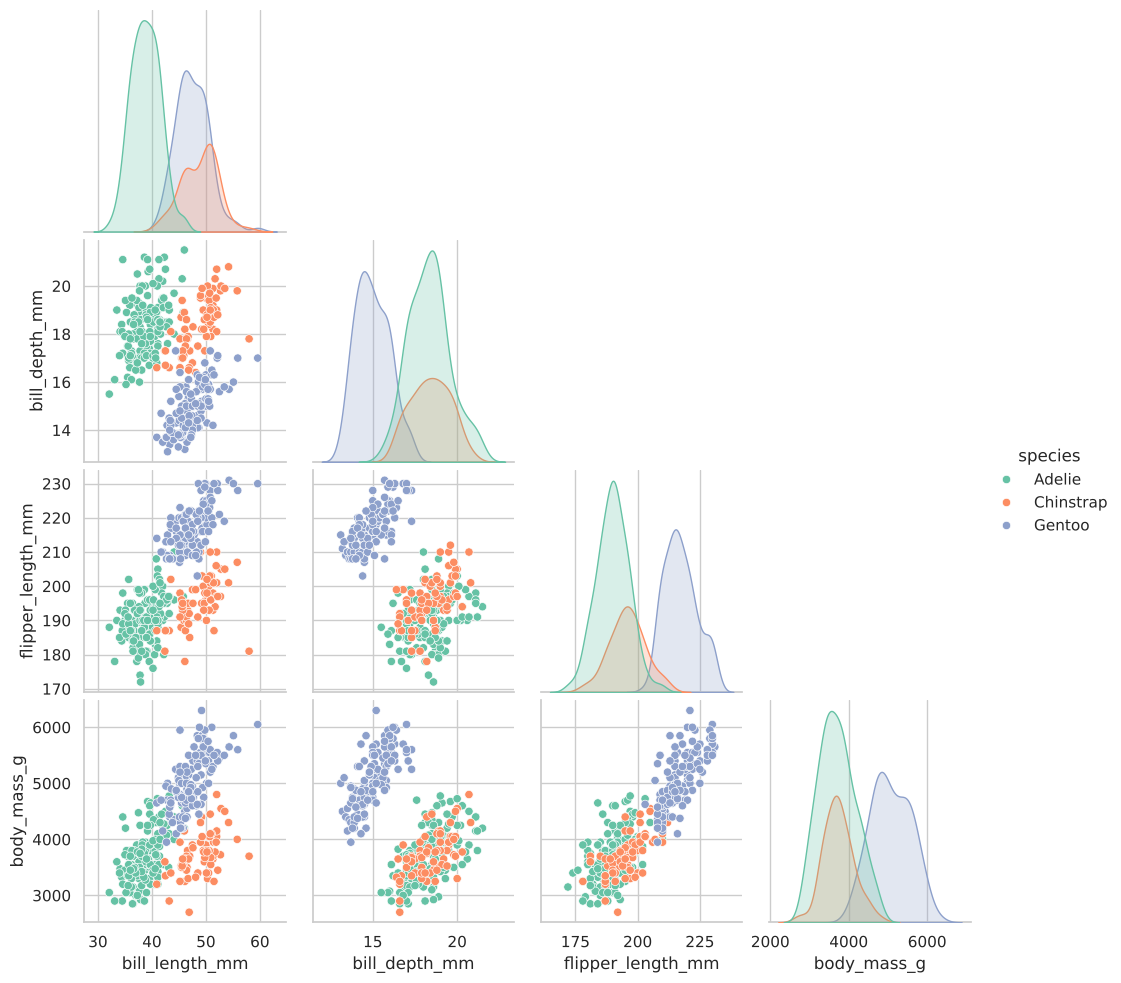

In [20]:
sns.pairplot(df, vars=num_cols, hue="species", corner=True)
plt.show()

**Observation:** Flipper length + bill depth separate Gentoo from the rest almost perfectly; bill length separates Adelie from Chinstrap.

## 7. Outlier detection (IQR method)

In [21]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()
pd.DataFrame({"outliers": {c: iqr_outliers(df[c]) for c in num_cols}})

,outliers
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0


**Observation:** No outliers by the IQR rule — the measurements are clean. Wide spreads come from the species mix, not from bad data.

## 8. Conclusions

1. **Data quality:** Only 2 rows were empty and 9 `gender` values missing; after cleaning, 342 usable rows with no duplicates or outliers.
2. **Gentoo stand apart** — heaviest, longest flippers, shallowest bills, and found only on Biscoe.
3. **Bill length** is the best single feature to tell Adelie from Chinstrap.
4. **Flipper length and body mass** are strongly linked (r ≈ 0.87).
5. **Males are heavier** in all three species.
6. **Simpson's Paradox:** bill length vs depth looks negative overall but is positive within every species — group-wise analysis matters.

**Next step:** These features separate species so clearly that a simple classifier (e.g., logistic regression or decision tree) should predict species with very high accuracy.